**PERSIAPAN LIBRARY**

In [1]:
import numpy as np
import matplotlib.pyplot as plt

**MENGHITUNG FUNGSI BESSEL**


Menghitung fungsi bessel $J_{n}(x)$ dilakukan dengan menyatakan berbagai nilai relatif dari fungsi bessel sendiri. Dengan menggunakan hubungan rekursi berikut:

$J_n(x) = \frac{2(n+1)}{x} J_{n+1}(x) - J_{n+2}(x)$

Metode perhitungan nya menggunakan metode *Backward Recurrent*, dimana dilakukan dari $J_n$ tertinggi hingga $J_0$. Penentuan orde tertinggi dimulainya *backward recurrent* ini menggunakan persamaan:

$n_{max} = int\left(x + C\sqrt{x}\right)$
dimana $10 \le C \le 20$

===============================================================================
Dalam kode ini, akan digunakan notasi basis $ n + 1 = m $, sehingga

$J_{m-1}(x) = \frac{2m}{x} J_{m}(x) - J_{m+1}(x)$

Selain itu, perlu dilakukan normalisasi dari fungsi Bessel yang sudah didapatkan, dengan normalisasi:

$J_0 + 2\sum_{n=0}^{n_{max}} J_{2n} = 1$

In [2]:
def calculate_bessel(x, nmax, guess_value):
  """
  Menghitung fungsi Bessel J_n(x) menggunakan metode rekursi mundur.
  Argumen:
      x (float): Nilai x di suatu titik untuk fungsi Bessel.
      nmax (int): Maksimum nilai n untuk rekursi mundur.
  Hasilnya:
      bessel (numpy array): Array berisi nilai J_n(x) untuk n = 0 hingga nmax.
  """

  """
  Pertama tentukan dulu orde tertinggi dari fungsi Bessel.
  Sediakan juga kolom kosong untuk menyimpan nilai dari Fungsi Bessel.
  """
  n_start = int(nmax + x + (10 * np.sqrt(x)))  # Menentukan n_start
  # print(f"Mulai dari orde ke-{n_start}")
  bessel  = np.zeros(nmax + 1)                 # Array untuk menyimpan hasil fungsi Bessel

  """
  Inisiasi nilai awal dari bessel tertinggi dan bessel selanjutnya
  Inisial juga akumulasi orde genap
  """
  jmp = 0.0         # Nilai bessel tertinggi
  jm  = guess_value # Nilai selenjutnya yang sedikit lebih kecil
  fn  = 0.0         # Nilai inisial jumlahan Bessel berorde genap

  """
  Kode Utama dalam perhitungan fungsi Bessel
  """
  for m in range(n_start, 0, -1):
    # print(f'Sekarang orde ke-{m}')
    jmn   = (2.0 * m / x) * jm - jmp             # Code Rekursi
    # print(f'Orde ke-{m} nilainya adalah: {jmn} (jmn)')
    if m % 2 == 0:                               # Mengecek apakah orde yang dihitung sedang genap, jika iya
      fn += jm                                   # Tambahkan nilai Bessel ini kedalam jumlahan
    if m <= nmax:                                # Jika orde yang dihitung lebih kecil dari orde yang ingin dihitung
      bessel[m] = jm                             # Masukan kedalam list array
    jmp = jm                                     # Posisi jmp diganti oleh jm
    jm  = jmn                                    # Posisi jm diganti oleh jmn
    # print(f'Akumulasi orde genap       : {fn}')
    # print('===================================================================')
                                                  # Mulai lanjut menghitung jmn yang baru
    if abs(fn) >= 1e50:                           # Jika akumulasi sudah sangat besar
      bessel /= fn                                # Nilai bessel yang ada dibagi saja
      jm     /= fn                                # Nilai jm nya juga
      jmn    /= fn                                # Dan jmn nya juga
      fn      = 1.0                               # Akumulasi di set sebesar 1

  # print('Deret Bessel saat ini')
  # print(bessel)
  # print()
  # print(f'suku Bessel saat ini: {len(bessel)}')
  # print('=====================================================================')

  """
  Menambahkan data terakhir yang sudah dihitung
  """
  # print(f'Akumulasi: {fn}')
  # print()
  bessel[0] = jmn                                 # Menambahkan data terakhir
  # print('Nilai kumpulan Bessel adalah')
  # print(bessel)
  # print()
  fn = 2.0 * fn + jmn                             # Term Normalisasi
  bessel /= fn
  # print('Bessel sudah ternormalisasi')
  return bessel

calculate_bessel(10, 10, 1e-15)

array([-0.24593576,  0.04347275,  0.25463031,  0.05837938, -0.21960269,
       -0.23406153, -0.01445884,  0.21671092,  0.31785413,  0.29185569,
        0.20748611])

Plot data dengan menggunakan berbagai nilai $x$

Masukan orde yang mau dihitung: 3
Masukan x_max yang mau diplot: 20
Masukan pendekatan nilai suku kedua (1e-): 1e-15


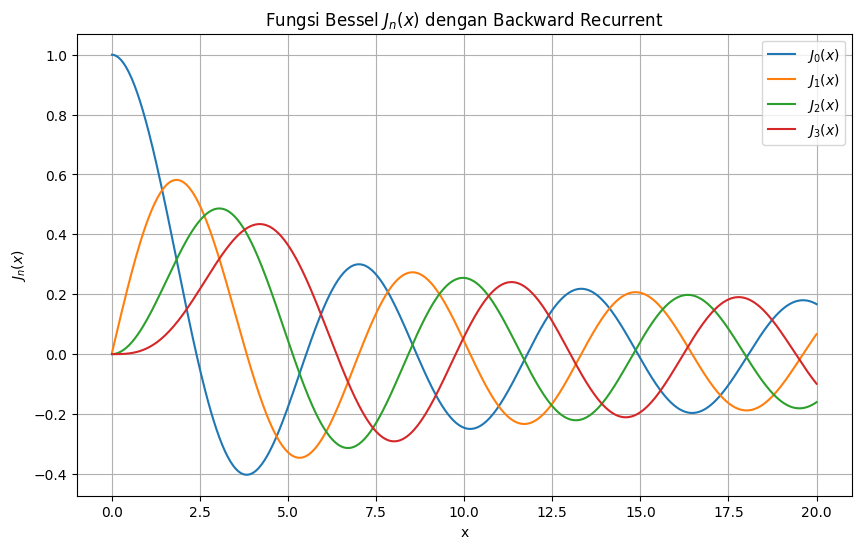

In [3]:
nmax  = int(input("Masukan orde yang mau dihitung: "))                   # Maksimum nilai n
xmax  = int(input("Masukan x_max yang mau diplot: "))                    # Maksimum nilai n
guess = float(input("Masukan pendekatan nilai suku kedua (1e-): "))

"""
Bagian mulai plot data
"""
x_values       = np.linspace(0.01, xmax, 500)                                   # Rentang sumbu x dilakukannya plot kurva
bessel_results = np.array([calculate_bessel(x, nmax, guess) for x in x_values]) # Mulai perhitungan
plt.figure(figsize=(10, 6))                                                     # Ukuran gambar
for n in range(nmax + 1):
    plt.plot(x_values, bessel_results[:, n], label=f"$J_{n}(x)$")               # Plot data
plt.xlabel("x")
plt.ylabel("$J_n(x)$")
plt.title("Fungsi Bessel $J_n(x)$ dengan Backward Recurrent")
plt.legend()
plt.grid()
plt.show()

**ASYMTOTIC FORM**

Digunakan ketika nila $x$ sangatlah besar:

$J_{n}(x)\approx \sqrt{\frac{2}{\pi x}} \cos{\left(x-\frac{n\pi}{2}-\frac{\pi}{4}\right)}$

dimana $x$ dikatakan besar jika $x>10n$

In [4]:
def asym(x, n):
  return np.sqrt(2/(np.pi * x)) * np.cos(x - (n * np.pi/2) - (np.pi/4))

Hitung untuk $J_{30}(x)$ dengan *backward recurrent* dan rumus Asymtothic

Masukan orde yang mau dihitung: 30
Masukan x_max yang mau diplot: 300
Masukan pendekatan nilai suku kedua (1e-): 1e-20


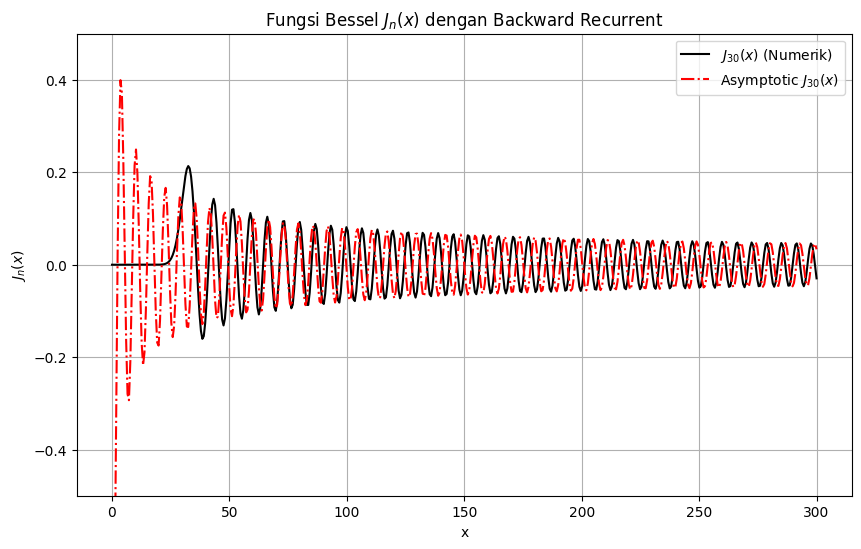

In [5]:
nmax  = int(input("Masukan orde yang mau dihitung: "))                   # Maksimum nilai n
xmax  = int(input("Masukan x_max yang mau diplot: "))                    # Maksimum nilai x
guess = float(input("Masukan pendekatan nilai suku kedua (1e-): "))

"""
Bagian mulai plot data
"""
x_values       = np.linspace(0.01, xmax, 500)                                   # Rentang sumbu x dilakukannya plot kurva
x_asym       = np.linspace(0.01, 300, 500)                                   # Rentang sumbu x dilakukannya plot kurva
bessel_results = np.array([calculate_bessel(x, nmax, guess) for x in x_values]) # Mulai perhitungan
bessel_nmax = bessel_results[:, -1]  # Hanya mengambil hasil untuk n_max
y_asym = asym(x_values, nmax)

plt.figure(figsize=(10, 6))                                                     # Ukuran gambar
plt.plot(x_values, bessel_nmax, label=f"$J_{{{nmax}}}(x)$ (Numerik)", linestyle='-', color='black')
plt.plot(x_asym, y_asym, label=f"Asymptotic $J_{{{nmax}}}(x)$", linestyle='-.', color='red')
plt.xlabel("x")
plt.ylabel("$J_n(x)$")
plt.ylim(-0.5, 0.5)
plt.title("Fungsi Bessel $J_n(x)$ dengan Backward Recurrent")
plt.legend()
plt.grid()
plt.show()

**ANALITIK**

Untuk Fungsi Analitik, nilai

$J_n(x) = \sum_{m=0}^{\infty} \frac{(-1)^{m}}{m!(m+n)!}\left(\frac{x}{2}\right)^{2m+n}$

dimana disini, notasi faktorial dinyatakan dengan bantuan library sehingga dapat lebih stabil dalam perhitungan

**Persiapan**

In [6]:
import numpy as np
import matplotlib.pyplot as plt
import math

**Perhitungan**

In [7]:
def analitik(x, batas, n):
    hasil = 0
    for m in range(batas):
        try:
            fakt1 = math.factorial(m)  # Gunakan math.factorial() yang lebih efisien
            fakt2 = math.factorial(m + n)
            hasil += ((-1) ** m) * ((x / 2) ** (2 * m + n)) / (fakt1 * fakt2)
        except OverflowError:
            break  # Jika faktorial terlalu besar, hentikan perhitungan
    return hasil

**Plot Kurva**

Masukkan orde yang mau dihitung: 30
Masukkan x_max yang mau diplot: 300
Masukkan batas jumlah suku: 500


<ipython-input-7-c815ec5642b8>:7: RuntimeWarning: overflow encountered in scalar power
  hasil += ((-1) ** m) * ((x / 2) ** (2 * m + n)) / (fakt1 * fakt2)
<ipython-input-7-c815ec5642b8>:7: RuntimeWarning: invalid value encountered in scalar add
  hasil += ((-1) ** m) * ((x / 2) ** (2 * m + n)) / (fakt1 * fakt2)


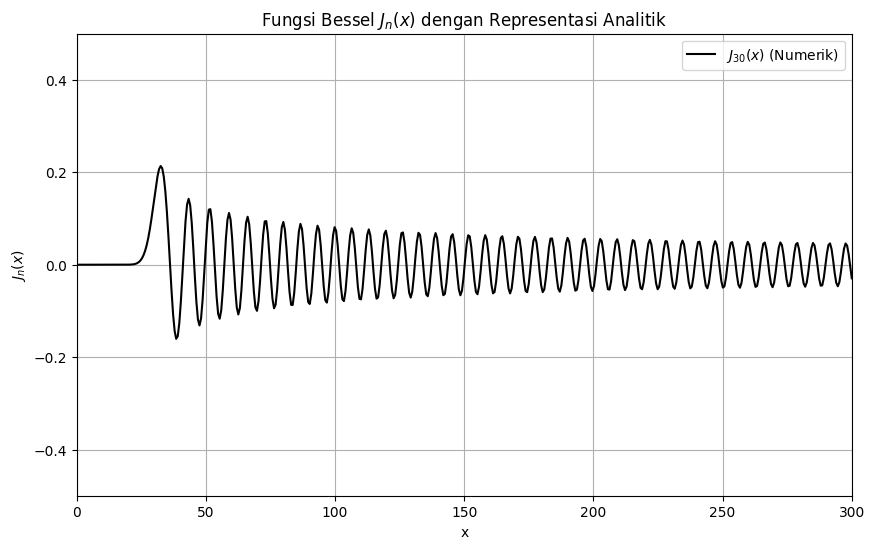

In [8]:

# Input dari pengguna
nmax = int(input("Masukkan orde yang mau dihitung: "))  # Maksimum nilai n
xmax = float(input("Masukkan x_max yang mau diplot: "))  # Maksimum nilai x
batas = int(input("Masukkan batas jumlah suku: "))  # Batas jumlah suku dalam deret

# Rentang x
x_values = np.linspace(0.01, xmax, 500)

# Hitung fungsi Bessel untuk setiap n dari 0 hingga nmax
plt.figure(figsize=(10, 6))
bessel_results1 = np.array([analitik(x, batas, n) for x in x_values])
bessel_nmax1 = bessel_results[:, -1]  # Hanya mengambil hasil untuk n_max
plt.plot(x_values, bessel_nmax1, label=f"$J_{{{nmax}}}(x)$ (Numerik)", linestyle='-', color='black')
# Konfigurasi plot
plt.xlabel("x")
plt.ylabel("$J_{n}(x)$")
plt.ylim(-0.5, 0.5)
plt.xlim(0, 300)
plt.title("Fungsi Bessel $J_{n}(x)$ dengan Representasi Analitik")
plt.legend()
plt.grid()
plt.show()